<a href="https://colab.research.google.com/github/Ashwini4856/BIS_LAB/blob/main/cuckooSearch_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

SOLAR PANEL TILT ANGLE OPTIMIZATION
----------------------------------
Iteration: 1 Best Energy: 1096.15
Iteration: 2 Best Energy: 1096.15
Iteration: 3 Best Energy: 1096.15
Iteration: 4 Best Energy: 1096.15
Iteration: 5 Best Energy: 1096.15
Iteration: 6 Best Energy: 1096.15
Iteration: 7 Best Energy: 1097.21
Iteration: 8 Best Energy: 1121.16
Iteration: 9 Best Energy: 1121.16
Iteration: 10 Best Energy: 1121.16
Iteration: 11 Best Energy: 1121.16
Iteration: 12 Best Energy: 1121.16
Iteration: 13 Best Energy: 1121.16
Iteration: 14 Best Energy: 1121.16
Iteration: 15 Best Energy: 1121.16
Iteration: 16 Best Energy: 1121.16
Iteration: 17 Best Energy: 1121.16
Iteration: 18 Best Energy: 1121.16
Iteration: 19 Best Energy: 1121.16
Iteration: 20 Best Energy: 1121.16
Iteration: 21 Best Energy: 1128.37
Iteration: 22 Best Energy: 1128.37
Iteration: 23 Best Energy: 1128.37
Iteration: 24 Best Energy: 1128.37
Iteration: 25 Best Energy: 1128.37
Iteration: 26 Best Energy: 1128.37
Iteration: 27 Best Energy: 1

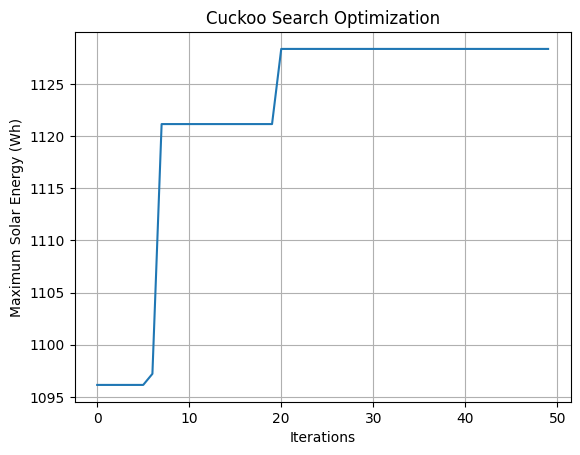

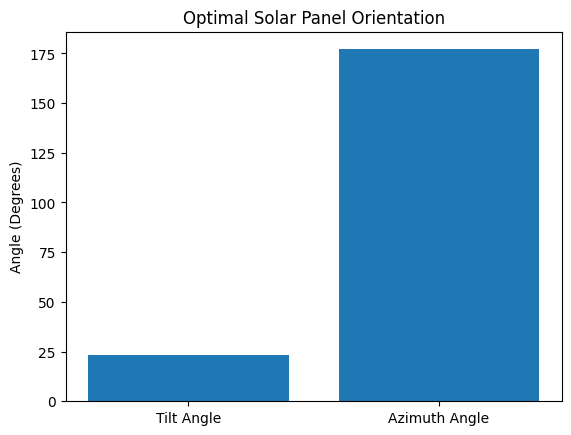

In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

# Cuckoo Search Parameters
N = 25
ITERATIONS = 50
PA = 0.25
ALPHA = 0.01

# Solar Panel Parameters
AREA = 2.0
EFFICIENCY = 0.20
ALBEDO = 0.2
NOCT = 45
TEMP_COEFF = -0.004

# Sample solar radiation dataset
data = pd.DataFrame({
    'ghi': [200, 400, 650, 800, 750, 500, 250],
    'dni': [150, 300, 500, 650, 600, 350, 150],
    'dhi': [50, 100, 150, 150, 150, 150, 100],
    'solar_zenith': [75, 55, 35, 20, 30, 50, 70],
    'solar_azimuth': [100, 120, 150, 180, 210, 240, 260],
    'temperature': [25, 28, 30, 32, 31, 29, 26]
})

# Fitness Function
def fitness(solution):

    tilt, azimuth = solution

    tilt = np.radians(tilt)
    azimuth = np.radians(azimuth)

    zenith = np.radians(data['solar_zenith'])
    sun_azimuth = np.radians(data['solar_azimuth'])

    ghi = data['ghi'].values
    dni = data['dni'].values
    dhi = data['dhi'].values
    temp = data['temperature'].values

    cos_aoi = (
        np.cos(zenith) * np.cos(tilt)
        + np.sin(zenith) * np.sin(tilt)
        * np.cos(sun_azimuth - azimuth)
    )

    beam = dni * np.maximum(cos_aoi, 0)

    diffuse = dhi * (1 + np.cos(tilt)) / 2

    reflected = (
        ghi * ALBEDO * (1 - np.cos(tilt)) / 2
    )

    poa = beam + diffuse + reflected

    cell_temp = temp + ((NOCT - 20) / 800) * poa

    power = (
        AREA * EFFICIENCY * poa
        * (1 + TEMP_COEFF * (cell_temp - 25))
    )

    power = np.maximum(power, 0)

    return np.sum(power)


# Levy Flight Function
def levy_flight():

    beta = 1.5

    sigma = (
        math.gamma(1 + beta)
        * math.sin(math.pi * beta / 2)
        / (
            math.gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma, 2)
    v = np.random.normal(0, 1, 2)

    return u / (np.abs(v) ** (1 / beta))


# Cuckoo Search Algorithm
def cuckoo_search():

    nests = np.random.uniform(
        [0, 0], [60, 360], (N, 2)
    )

    scores = np.array([fitness(x) for x in nests])

    best_index = np.argmax(scores)
    best_nest = nests[best_index].copy()
    best_score = scores[best_index]

    history = []

    for iteration in range(ITERATIONS):

        for i in range(N):

            new_nest = (
                nests[i]
                + ALPHA * levy_flight()
                * (nests[i] - best_nest)
            )

            new_nest[0] = np.clip(new_nest[0], 0, 60)
            new_nest[1] = new_nest[1] % 360

            new_score = fitness(new_nest)

            j = np.random.randint(N)

            if new_score > scores[j]:
                nests[j] = new_nest
                scores[j] = new_score

            if new_score > best_score:
                best_score = new_score
                best_nest = new_nest.copy()

        # Abandon poor nests
        for i in range(N):

            if np.random.rand() < PA:

                nests[i] = np.random.uniform(
                    [0, 0], [60, 360]
                )

                scores[i] = fitness(nests[i])

        best_index = np.argmax(scores)

        if scores[best_index] > best_score:
            best_score = scores[best_index]
            best_nest = nests[best_index].copy()

        history.append(best_score)

        print(
            "Iteration:", iteration + 1,
            "Best Energy:", round(best_score, 2)
        )

    return best_nest, best_score, history


# Main Program
print("SOLAR PANEL TILT ANGLE OPTIMIZATION")
print("----------------------------------")

best_solution, best_energy, history = cuckoo_search()

# Baseline comparison
baseline_energy = fitness([15, 180])

improvement = (
    (best_energy - baseline_energy)
    / baseline_energy
) * 100

print("\nOPTIMIZATION RESULTS")
print("--------------------")

print("Optimal Tilt Angle:",
      round(best_solution[0], 2), "degrees")

print("Optimal Azimuth Angle:",
      round(best_solution[1], 2), "degrees")

print("Maximum Solar Energy:",
      round(best_energy, 2), "Wh")

print("Baseline Solar Energy:",
      round(baseline_energy, 2), "Wh")

print("Energy Improvement:",
      round(improvement, 2), "%")

# Plot convergence graph
plt.plot(history)
plt.xlabel("Iterations")
plt.ylabel("Maximum Solar Energy (Wh)")
plt.title("Cuckoo Search Optimization")
plt.grid()
plt.show()

# Display optimal configuration
plt.bar(
    ["Tilt Angle", "Azimuth Angle"],
    [best_solution[0], best_solution[1]]
)

plt.ylabel("Angle (Degrees)")
plt.title("Optimal Solar Panel Orientation")
plt.show()
